# ANA500 Micro-Project 4: Can Recurrent Neural Networks Forecast Tomorrow's Electricity Demand?

**Dataset:** Hourly Energy Consumption, PJM East region, Kaggle (https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption)
**Tools:** Python, NumPy, pandas, statsmodels, scikit-learn, TensorFlow/Keras, Matplotlib, Seaborn
**Author:** Zeena Keshwji  |  **Date:** November 6, 2026

## Problem statement
Electricity cannot be stored cheaply at grid scale, so generation has to match demand hour by hour. PJM East demand
in this data swings between about 14,500 MW and 62,000 MW. Under-forecasting risks shortages and expensive
last-minute generation; over-forecasting wastes committed capacity. We want to **predict each of the next 24 hourly
load values (in megawatts) from the past load history and the calendar.**

## Hypothesis
Demand is a repeating pattern with memory, so a model that reads the recent load *as a sequence* should forecast it best:
* **H1 (cycles):** Load has strong daily, weekly and annual cycles.
* **H2 (deep learning vs. baselines):** A recurrent network beats the seasonal-naive forecast and linear (ridge) regression.
* **H3 (recurrence and gating):** Gated recurrent networks (LSTM, GRU) beat a plain RNN and a feed-forward network given the same inputs.
* **H4 (memory length):** A one-week input window beats a one-day window.
* **H5 (error structure):** The largest errors fall in summer peaks and on holidays, because the data has no weather variable.

Models are compared on a chronological hold-out test set (2017 to August 2018). Differences in error are tested with a
paired block bootstrap at alpha = 0.05.

## Step 0. Set up the environment

In [1]:
# Quiet TensorFlow's start-up logging; must be set before TensorFlow is imported
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Core data handling
import numpy as np
import pandas as pd

# Visualization (Matplotlib + Seaborn)
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Time-series diagnostics and the U.S. federal holiday calendar
from statsmodels.tsa.stattools import acf
from scipy.stats import mannwhitneyu
from pandas.tseries.holiday import USFederalHolidayCalendar

# Machine-learning baselines from Micro-Project 3
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score

# Deep learning
import tensorflow as tf
import keras
from keras import layers

import time
import urllib.request
import zipfile
import warnings
warnings.filterwarnings("ignore")

# One consistent look: teal = the data / best model, coral = highlights, gray = baselines
sns.set_theme(style="whitegrid", context="notebook")
TEAL, CORAL, GRAY = "#17877B", "#E4572E", "#8A9099"
os.makedirs("figures", exist_ok=True)   # every chart is also saved for the slide deck
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)

# Deterministic TensorFlow ops, so that re-running this notebook gives the same numbers
tf.config.experimental.enable_op_determinism()
SEEDS = [42, 7, 2026]                   # every neural network is trained once per seed
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.20.0 | Keras 3.10.0


## Step 1. Acquire
**Identify:** the Kaggle "Hourly Energy Consumption" dataset (user *robikscube*), which holds hourly load published by
PJM Interconnection, the grid operator for much of the eastern U.S. We use the PJM East region file, the longest series.
**Retrieve:** if the CSV is not on disk, the cell downloads the ZIP from Kaggle's public endpoint and extracts it.
**Query:** the file is read into a pandas DataFrame.

In [2]:
DATA_PATH = "data/PJME_hourly.csv"
DATA_URL = "https://www.kaggle.com/api/v1/datasets/download/robikscube/hourly-energy-consumption"

# Retrieve the file only if it is not already on disk, so the notebook is reproducible
if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "data/hourly-energy-consumption.zip")
    with zipfile.ZipFile("data/hourly-energy-consumption.zip") as z:
        z.extract("PJME_hourly.csv", "data")

# Query: load the file and parse the timestamp column
raw = pd.read_csv(DATA_PATH, parse_dates=["Datetime"])
print("Shape:", raw.shape)
print("Range:", raw["Datetime"].min(), "to", raw["Datetime"].max())
print("Already in time order?", raw["Datetime"].is_monotonic_increasing)
raw.head()

Shape: (145366, 2)
Range: 2002-01-01 01:00:00 to 2018-08-03 00:00:00
Already in time order? False


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


## Step 2. Prepare
### 2a. Clean the time index
A recurrent network assumes evenly spaced steps, so the index must be a perfect hourly grid. We check for missing values,
duplicate timestamps and gaps.

In [3]:
# Quality checks on the raw file
n_null = int(raw["PJME_MW"].isna().sum())
dups = raw[raw["Datetime"].duplicated(keep=False)].sort_values("Datetime")
print("Missing load values:", n_null)
print("Rows sharing a timestamp:", len(dups), "on", dups["Datetime"].dt.date.nunique(), "dates (fall daylight-saving hour)")

# Sort by time; the two readings in a repeated daylight-saving hour are averaged
load = raw.groupby("Datetime")["PJME_MW"].mean().sort_index()

# Reindex onto a complete hourly grid to expose gaps
load = load.asfreq("H")
gaps = load[load.isna()].index
print("Hours missing from the grid:", len(gaps), "| by month:", gaps.month.value_counts().sort_index().to_dict())

# Gaps are isolated single hours (mostly the spring daylight-saving hour), so time interpolation is safe
longest_gap = load.isna().astype(int).groupby(load.notna().cumsum()).sum().max()
print("Longest gap (hours):", longest_gap)
load = load.interpolate("time")
print("Clean series:", len(load), "hours, missing now:", int(load.isna().sum()))
print(load.describe().round(0).to_string())
print("Lowest reading:", load.idxmin(), "(Hurricane Sandy) =", int(load.min()), "MW")
print("Highest reading:", load.idxmax(), "=", int(load.max()), "MW")

Missing load values: 0
Rows sharing a timestamp: 8 on 4 dates (fall daylight-saving hour)
Hours missing from the grid: 30 | by month: {3: 12, 4: 5, 10: 5, 11: 7, 12: 1}
Longest gap (hours): 1
Clean series: 145392 hours, missing now: 0
count    145392.0
mean      32079.0
std        6464.0
min       14544.0
25%       27571.0
50%       31420.0
75%       35647.0
max       62009.0
Lowest reading: 2012-10-30 04:00:00 (Hurricane Sandy) = 14544 MW
Highest reading: 2006-08-02 17:00:00 = 62009 MW


### 2b. Explore: testing H1
We look at the long-run series, the typical shape by hour and month, and the autocorrelation function.

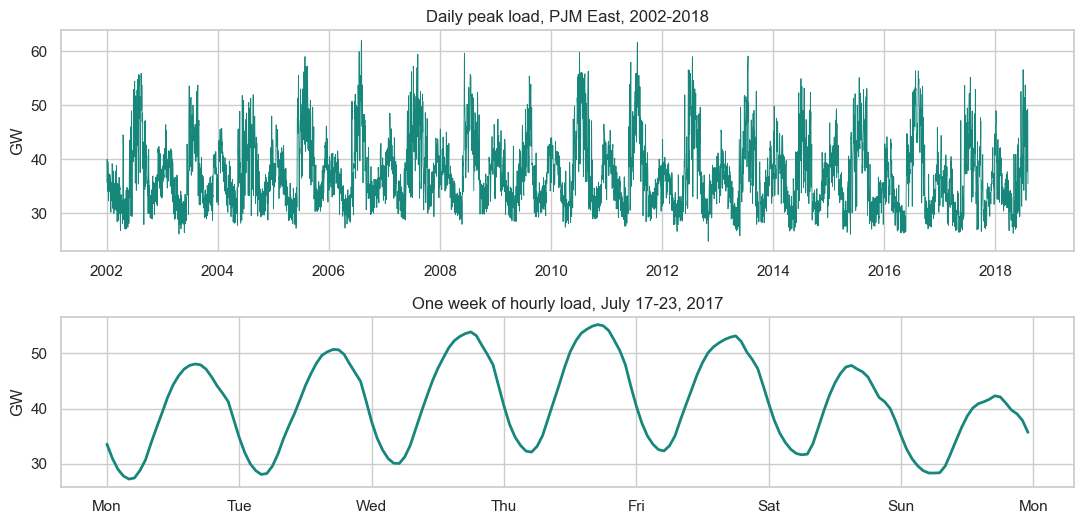

In [4]:
# Figure 1: the full series as daily peaks, with one sample week below it
fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), gridspec_kw={"height_ratios": [1.3, 1]})
daily_peak = load.resample("D").max()
axes[0].plot(daily_peak.index, daily_peak / 1000, color=TEAL, lw=0.6)
axes[0].set(title="Daily peak load, PJM East, 2002-2018", ylabel="GW")
week = load["2017-07-17":"2017-07-23"]
axes[1].plot(week.index, week / 1000, color=TEAL, lw=2)
axes[1].set(title="One week of hourly load, July 17-23, 2017", ylabel="GW")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%a"))
axes[1].xaxis.set_major_locator(mdates.DayLocator())
plt.tight_layout(); plt.savefig("figures/01_load_overview.png", dpi=200); plt.show()

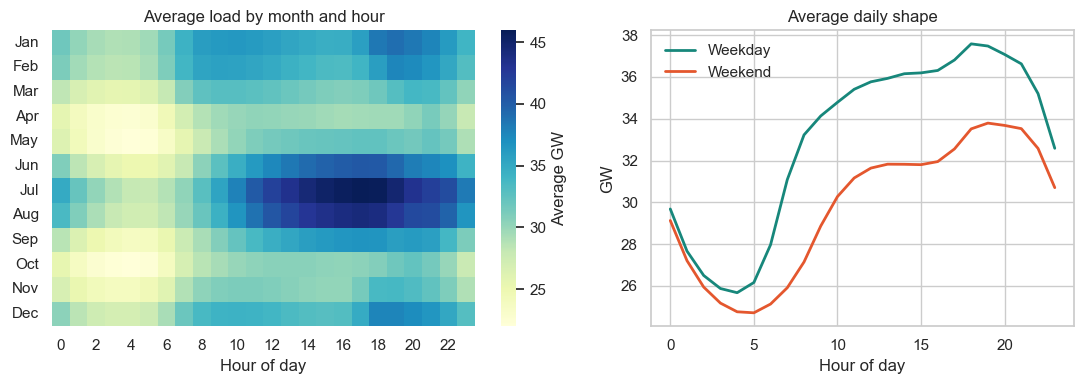

Daily cycle: lowest hour 4:00 = 25,415 MW, highest hour 19:00 = 36,427 MW
Annual cycle: lowest month 4 = 27,861 MW, highest month 7 = 37,882 MW
Weekday mean 32,996 MW vs. weekend mean 29,784 MW


In [5]:
# Calendar view: average load by hour and month, and by hour for weekdays vs. weekends
profile = load.groupby([load.index.month, load.index.hour]).mean().unstack() / 1000
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(profile, cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "Average GW"},
            yticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axes[0].set(title="Average load by month and hour", xlabel="Hour of day", ylabel="")
axes[0].tick_params(axis="y", rotation=0)
is_weekend = load.index.dayofweek >= 5
for mask, label, color in [(~is_weekend, "Weekday", TEAL), (is_weekend, "Weekend", CORAL)]:
    prof = load[mask].groupby(load[mask].index.hour).mean() / 1000
    axes[1].plot(prof.index, prof.values, color=color, lw=2, label=label)
axes[1].set(title="Average daily shape", xlabel="Hour of day", ylabel="GW")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/02_calendar_patterns.png", dpi=200); plt.show()

# Size of each cycle in plain numbers
hour_mean = load.groupby(load.index.hour).mean()
month_mean = load.groupby(load.index.month).mean()
print(f"Daily cycle: lowest hour {hour_mean.idxmin()}:00 = {hour_mean.min():,.0f} MW, highest hour {hour_mean.idxmax()}:00 = {hour_mean.max():,.0f} MW")
print(f"Annual cycle: lowest month {month_mean.idxmin()} = {month_mean.min():,.0f} MW, highest month {month_mean.idxmax()} = {month_mean.max():,.0f} MW")
print(f"Weekday mean {load[~is_weekend].mean():,.0f} MW vs. weekend mean {load[is_weekend].mean():,.0f} MW")

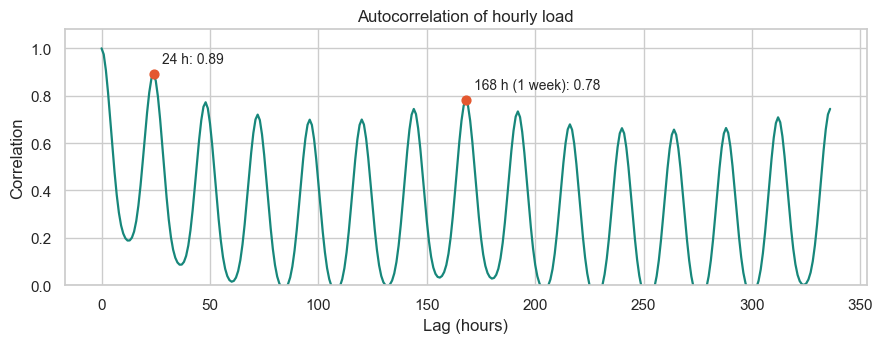

ACF: lag 1 = 0.975, lag 12 = 0.189, lag 24 = 0.891, lag 168 = 0.782


In [6]:
# Autocorrelation out to two weeks: peaks at multiples of 24 and at 168 show the cycles
lags = 24 * 14
ac = acf(load, nlags=lags, fft=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(range(lags + 1), ac, color=TEAL, lw=1.6)
for lag, text in [(24, "24 h"), (168, "168 h (1 week)")]:
    ax.scatter([lag], [ac[lag]], color=CORAL, zorder=3, s=40)
    ax.annotate(f"{text}: {ac[lag]:.2f}", (lag, ac[lag]), xytext=(6, 8), textcoords="offset points", fontsize=10)
ax.set(title="Autocorrelation of hourly load", xlabel="Lag (hours)", ylabel="Correlation", ylim=(0, 1.08))
plt.tight_layout(); plt.savefig("figures/03_autocorrelation.png", dpi=200); plt.show()
print(f"ACF: lag 1 = {ac[1]:.3f}, lag 12 = {ac[12]:.3f}, lag 24 = {ac[24]:.3f}, lag 168 = {ac[168]:.3f}")

### 2c. Features and supervised windows
Each sample is one forecast. The model sees the **last 168 hours** of load with calendar features and the **calendar of
the next 24 hours** (known in advance), and predicts the **next 24 hourly loads**. The calendar uses sine and cosine pairs
so that hour 23 sits next to hour 0 and December next to January, plus a flag for weekends and federal holidays.

**The split is chronological**, because a random split would leak the future into training:

| Set | Forecast target dates | Use |
|---|---|---|
| Train | 2002 to 2014 | Fit parameters and scalers |
| Validation | 2015 to 2016 | Early stopping, tuning, choosing the final model, calibrating intervals |
| Test | Jan 2017 to Aug 2, 2018 | Final results only |

Training windows start every 6 hours to give the networks more examples. Validation and test forecasts are all issued at
midnight, one per day, so every day is scored once.

In [7]:
# Calendar features for every hour in the series
idx = load.index
holidays = USFederalHolidayCalendar().holidays(start=idx.min(), end=idx.max())
is_off = ((idx.dayofweek >= 5) | idx.normalize().isin(holidays)).astype("float32")
calendar = np.column_stack([
    np.sin(2 * np.pi * idx.hour / 24), np.cos(2 * np.pi * idx.hour / 24),
    np.sin(2 * np.pi * idx.dayofweek / 7), np.cos(2 * np.pi * idx.dayofweek / 7),
    np.sin(2 * np.pi * idx.dayofyear / 365.25), np.cos(2 * np.pi * idx.dayofyear / 365.25),
    is_off,
]).astype("float32")

# Split boundaries, as positions in the hourly array
HORIZON, WINDOW = 24, 168
VAL_START, TEST_START = idx.get_loc(pd.Timestamp("2015-01-01 00:00")), idx.get_loc(pd.Timestamp("2017-01-01 00:00"))

# Standardize load with TRAINING statistics only, so nothing is learned from later data
mu, sigma = load.iloc[:VAL_START].mean(), load.iloc[:VAL_START].std()
z = ((load.values - mu) / sigma).astype("float32")
past_features = np.column_stack([z, calendar])    # 8 features per past hour
print(f"Training mean {mu:,.0f} MW, std {sigma:,.0f} MW")

# Forecast origins: position t means "forecast hours t to t+23 using hours before t"
positions = np.arange(WINDOW, len(load) - HORIZON + 1)
hours = idx.hour[positions]
train_o = positions[(positions + HORIZON <= VAL_START) & (hours % 6 == 0)]
val_o = positions[(positions >= VAL_START) & (positions + HORIZON <= TEST_START) & (hours == 0)]
test_o = positions[(positions >= TEST_START) & (hours == 0)]


def make_windows(origins, window=WINDOW):
    """Returns past inputs (n, window, 8), future calendar (n, 24, 7) and targets (n, 24)."""
    past = past_features[origins[:, None] + np.arange(-window, 0)]
    future = calendar[origins[:, None] + np.arange(HORIZON)]
    target = z[origins[:, None] + np.arange(HORIZON)]
    return past, future, target


Xp_tr, Xf_tr, y_tr = make_windows(train_o)
Xp_va, Xf_va, y_va = make_windows(val_o)
Xp_te, Xf_te, y_te = make_windows(test_o)
print("Train:", Xp_tr.shape, "| Validation:", Xp_va.shape, "| Test:", Xp_te.shape, "| Targets:", y_te.shape)
print("Test days:", idx[test_o[0]].date(), "to", idx[test_o[-1]].date())

# Leakage check: no training target reaches the validation period, no validation target reaches test
assert train_o.max() + HORIZON <= VAL_START and val_o.max() + HORIZON <= TEST_START

to_mw = lambda a: a * sigma + mu      # converts standardized values back to megawatts
actual_val, actual_test = to_mw(y_va), to_mw(y_te)

Training mean 32,288 MW, std 6,453 MW
Train: (18960, 168, 8) | Validation: (731, 168, 8) | Test: (579, 168, 8) | Targets: (579, 24)
Test days: 2017-01-01 to 2018-08-02


## Step 3. Analyze data
### 3a. Technique and evaluation
This is multi-output **regression**: 24 continuous targets per forecast. Every trained model is fitted with both a 24-hour and
a 168-hour input window, and keeps the window that scores better on validation, so no model gets an information advantage.

| Model | Type | Why it is here |
|---|---|---|
| Same hour yesterday | Baseline | The simplest daily-cycle forecast |
| Seasonal naive | Baseline | "Same hour last week"; any useful model must beat it |
| Ridge regression | Linear ML | The linear baseline carried over from Micro-Project 3 |
| Gradient boosting | Tree ML | A strong non-neural benchmark, one model per horizon hour |
| Dense network (MLP) | Deep learning | Same inputs, flattened, so it has no notion of order |
| Simple RNN | Deep learning | Recurrence without gates |
| LSTM | Deep learning | Gated memory |
| GRU | Deep learning | Lighter gated memory |
| Seq2Seq LSTM | Deep learning | An encoder reads the past, a decoder steps through the next 24 hours |

Metrics: **MAE** in MW (the main metric), **RMSE**, **MAPE**, **R²**, and the **peak error**, the percent error on each
day's highest hour, which is the number that matters most for capacity planning.

In [8]:
def metrics(actual, pred):
    """Accuracy on (days, 24) arrays in MW, including error on each day's peak load."""
    err = pred - actual
    peak_err = np.abs(pred.max(axis=1) - actual.max(axis=1)) / actual.max(axis=1)
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()),
            "MAPE %": 100 * np.abs(err / actual).mean(), "R2": r2_score(actual.ravel(), pred.ravel()),
            "Peak MAPE %": 100 * peak_err.mean()}


forecasts_val, forecasts_test = {}, {}   # (model, window) -> (days, 24) forecast in MW
WINDOWS = [24, 168]

# Naive baselines: each hour repeats its value from one day or one week earlier
naive = lambda origins, lag: load.values[origins[:, None] + np.arange(HORIZON) - lag]
for name, lag in [("Same hour yesterday", 24), ("Seasonal naive", 168)]:
    forecasts_val[(name, lag)], forecasts_test[(name, lag)] = naive(val_o, lag), naive(test_o, lag)

# Flattened inputs for models with no notion of sequence: past loads + the next 24 hours' calendar
flat = lambda Xp, Xf, w: np.column_stack([Xp[:, -w:, 0], Xf.reshape(len(Xf), -1)])

for w in WINDOWS:
    F_tr, F_va, F_te = flat(Xp_tr, Xf_tr, w), flat(Xp_va, Xf_va, w), flat(Xp_te, Xf_te, w)

    # Ridge regression: the penalty is chosen on the validation set
    scores = {a: metrics(actual_val, to_mw(Ridge(alpha=a).fit(F_tr, y_tr).predict(F_va)))["MAE"]
              for a in [0.01, 0.1, 1, 10, 100, 1000]}
    best_alpha = min(scores, key=scores.get)
    ridge = Ridge(alpha=best_alpha).fit(F_tr, y_tr)
    forecasts_val[("Ridge", w)], forecasts_test[("Ridge", w)] = to_mw(ridge.predict(F_va)), to_mw(ridge.predict(F_te))
    print(f"Ridge, {w} h window: alpha = {best_alpha}, validation MAE = {scores[best_alpha]:,.0f} MW")

    # Gradient boosting: one model per horizon hour, on the past loads plus that hour's calendar
    t0 = time.time()
    gb_val, gb_test = np.zeros_like(y_va), np.zeros_like(y_te)
    for h in range(HORIZON):
        rows = lambda Xp, Xf: np.column_stack([Xp[:, -w:, 0], Xf[:, h, :]])
        gb = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, random_state=42)
        gb.fit(rows(Xp_tr, Xf_tr), y_tr[:, h])
        gb_val[:, h], gb_test[:, h] = gb.predict(rows(Xp_va, Xf_va)), gb.predict(rows(Xp_te, Xf_te))
    forecasts_val[("Gradient boosting", w)], forecasts_test[("Gradient boosting", w)] = to_mw(gb_val), to_mw(gb_test)
    print(f"Gradient boosting, {w} h window: validation MAE = {metrics(actual_val, to_mw(gb_val))['MAE']:,.0f} MW ({time.time() - t0:.0f} s)")

Ridge, 24 h window: alpha = 0.01, validation MAE = 1,332 MW


Gradient boosting, 24 h window: validation MAE = 1,248 MW (36 s)


Ridge, 168 h window: alpha = 0.01, validation MAE = 1,245 MW


Gradient boosting, 168 h window: validation MAE = 1,257 MW (66 s)


### 3b. Build the neural networks
Each architecture is a small Keras functional model with two inputs, the past window and the future calendar. Training uses
Adam, mean squared error on the standardized load, early stopping on validation loss (best weights restored), and a
learning-rate cut when validation loss stalls.

In [9]:
def build_model(kind, window=WINDOW, units=64):
    """Builds one of the five network types. Output: the next 24 hourly loads (standardized)."""
    past = keras.Input((window, 8), name="past")
    future = keras.Input((HORIZON, 7), name="future_calendar")
    future_flat = layers.Flatten()(future)

    if kind == "MLP":                       # order-blind: the window is flattened
        x = layers.Concatenate()([layers.Flatten()(past), future_flat])
        x = layers.Dense(256, activation="relu")(x)
        x = layers.Dropout(0.1)(x)
        x = layers.Dense(128, activation="relu")(x)
        out = layers.Dense(HORIZON)(x)
    elif kind == "Seq2Seq LSTM":            # encoder summarizes the past, decoder walks the next 24 hours
        _, h, c = layers.LSTM(units, return_state=True)(past)
        x = layers.LSTM(units, return_sequences=True)(future, initial_state=[h, c])
        out = layers.Reshape((HORIZON,))(layers.TimeDistributed(layers.Dense(1))(x))
    else:                                   # single recurrent layer, then a dense head with the future calendar
        rnn = {"Simple RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[kind]
        x = layers.Concatenate()([rnn(units)(past), future_flat])
        x = layers.Dense(64, activation="relu")(x)
        out = layers.Dense(HORIZON)(x)
    return keras.Model([past, future], out, name=kind.replace(" ", "_"))


def train(kind, seed, window=WINDOW, units=64, max_epochs=60):
    """Trains one network with a fixed seed and returns the model and its history."""
    keras.utils.set_random_seed(seed)
    model = build_model(kind, window, units)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)]
    hist = model.fit([Xp_tr[:, -window:], Xf_tr], y_tr, validation_data=([Xp_va[:, -window:], Xf_va], y_va),
                     epochs=max_epochs, batch_size=256, callbacks=callbacks, verbose=0)
    return model, hist


build_model("LSTM").summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ past (InputLayer)   │ (None, 168, 8)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_calendar     │ (None, 24, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     18,688 │ past[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 168)       │          0 │ future_calendar[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 232)       │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     14,912 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 24)        │      1,560 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 35,160 (137.34 KB)

 Trainable params: 35,160 (137.34 KB)

 Non-trainable params: 0 (0.00 B)

### 3c. Tune the layer width
A small grid on the **validation set only**, using the LSTM with the fast 24-hour window. The chosen width is used by all
recurrent networks. Single-seed differences this small are close to noise, so the point is only to rule out a poor size.

In [10]:
grid = []
for units in [32, 64, 128]:
    t0 = time.time()
    m, h = train("LSTM", SEEDS[0], 24, units)
    val_pred = to_mw(m.predict([Xp_va[:, -24:], Xf_va], verbose=0))
    grid.append({"Units": units, "Parameters": m.count_params(), "Val MAE": metrics(actual_val, val_pred)["MAE"],
                 "Epochs": len(h.history["loss"]), "Seconds": round(time.time() - t0)})
grid = pd.DataFrame(grid)
print(grid.round(1).to_string(index=False))
UNITS = int(grid.loc[grid["Val MAE"].idxmin(), "Units"])
print("Chosen width:", UNITS)

 Units  Parameters     Val MAE  Epochs  Seconds
    32       19672 1225.300049      60       31
    64       35160 1221.199951      57       63
   128       90712 1234.699951      42       93
Chosen width: 64


### 3d. Train every network: 5 architectures x 2 windows x 3 seeds
Neural networks vary from run to run, so a single run is weak evidence. Each network and window is trained with three seeds.
The forecast used is the **average of the three** (a small ensemble), and the spread of single-seed MAE shows how stable it is.

*Iteration note:* a first run used one window for the networks, picked from a single seed, and stopped at a 40-epoch cap.
Those two design flaws were fixed here. Model selection still uses validation data only, but because that first run did show
test scores, the test set is not perfectly untouched.

In [11]:
DEEP = ["MLP", "Simple RNN", "LSTM", "GRU", "Seq2Seq LSTM"]
seed_rows, histories = [], {}
for kind in DEEP:
    for w in WINDOWS:
        val_runs, test_runs = [], []
        for seed in SEEDS:
            t0 = time.time()
            m, h = train(kind, seed, w, UNITS)
            val_runs.append(to_mw(m.predict([Xp_va[:, -w:], Xf_va], verbose=0)))
            test_runs.append(to_mw(m.predict([Xp_te[:, -w:], Xf_te], verbose=0)))
            histories.setdefault((kind, w), h.history)      # keep the first seed's learning curve
            seed_rows.append({"Model": kind, "Window": w, "Seed": seed, "Parameters": m.count_params(),
                              "Epochs": len(h.history["loss"]), "Val MAE": metrics(actual_val, val_runs[-1])["MAE"],
                              "Test MAE": metrics(actual_test, test_runs[-1])["MAE"], "Seconds": round(time.time() - t0)})
        forecasts_val[(kind, w)], forecasts_test[(kind, w)] = np.mean(val_runs, axis=0), np.mean(test_runs, axis=0)
        print(kind, w, "done")
seeds = pd.DataFrame(seed_rows)
print(seeds.round(1).to_string(index=False))

MLP 24 done


MLP 168 done


Simple RNN 24 done


Simple RNN 168 done


LSTM 24 done


LSTM 168 done


GRU 24 done


GRU 168 done


Seq2Seq LSTM 24 done


Seq2Seq LSTM 168 done
       Model  Window  Seed  Parameters  Epochs     Val MAE    Test MAE  Seconds
         MLP      24    42      128408      60 1180.099976 1345.699951       12
         MLP      24     7      128408      60 1186.199951 1352.800049       11
         MLP      24  2026      128408      48 1163.800049 1336.800049        9
         MLP     168    42      423320      51 1209.300049 1368.099976       17
         MLP     168     7      423320      55 1225.300049 1389.900024       17
         MLP     168  2026      423320      60 1194.000000 1352.699951       18
  Simple RNN      24    42       21144      60 1188.699951 1390.699951       21
  Simple RNN      24     7       21144      60 1205.199951 1373.500000       21
  Simple RNN      24  2026       21144      60 1185.900024 1397.800049       21
  Simple RNN     168    42       21144      60 1178.000000 1376.699951      120
  Simple RNN     168     7       21144      60 1187.800049 1352.099976      122
  Simple RNN     1

                        24      168
GRU                  1171.0  1165.0
Gradient boosting    1248.0  1257.0
LSTM                 1203.0  1211.0
MLP                  1160.0  1190.0
Ridge                1332.0  1245.0
Same hour yesterday  2137.0     NaN
Seasonal naive          NaN  3312.0
Seq2Seq LSTM         1190.0  1191.0
Simple RNN           1154.0  1151.0
Chosen windows: {'GRU': 168, 'Gradient boosting': 24, 'LSTM': 24, 'MLP': 24, 'Ridge': 168, 'Same hour yesterday': 24, 'Seasonal naive': 168, 'Seq2Seq LSTM': 24, 'Simple RNN': 168}


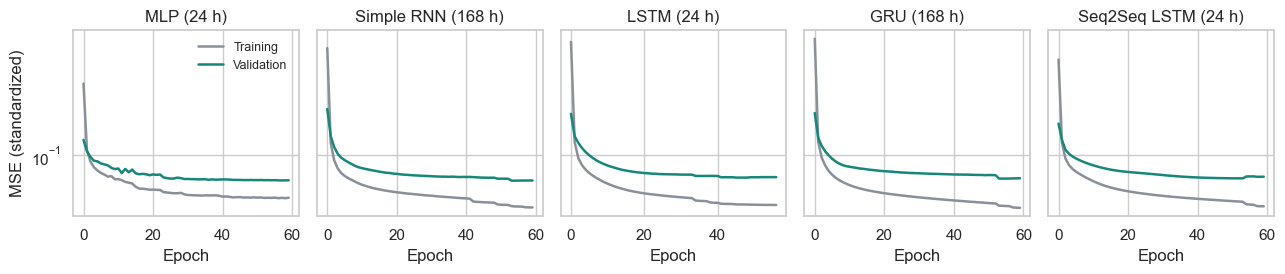

In [12]:
# Each model keeps the window with the lower VALIDATION error
val_mae = pd.Series({k: metrics(actual_val, v)["MAE"] for k, v in forecasts_val.items()})
best_window = val_mae.groupby(level=0).idxmin().map(lambda k: k[1]).to_dict()
print(val_mae.unstack().round(0).to_string())
print("Chosen windows:", best_window)

# Learning curves at each network's chosen window: loss should settle with no runaway gap
fig, axes = plt.subplots(1, 5, figsize=(13, 2.9), sharey=True)
for ax, kind in zip(axes, DEEP):
    hist = histories[(kind, best_window[kind])]
    ax.plot(hist["loss"], color=GRAY, lw=1.8, label="Training")
    ax.plot(hist["val_loss"], color=TEAL, lw=1.8, label="Validation")
    ax.set(title=f"{kind} ({best_window[kind]} h)", xlabel="Epoch", yscale="log")
axes[0].set_ylabel("MSE (standardized)")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("figures/04_learning_curves.png", dpi=200); plt.show()

### 3e. Choose the final model on validation, then open the test set
The final model is the one with the lowest **validation** MAE. Test results are reported for every model, but they played
no part in that choice.

In [13]:
# All windows are kept for the H4 test; the tables below use each model's chosen window
all_val, all_test = dict(forecasts_val), dict(forecasts_test)
forecasts_val = {m: all_val[(m, w)] for m, w in best_window.items()}
forecasts_test = {m: all_test[(m, w)] for m, w in best_window.items()}
val_table = pd.DataFrame({k: metrics(actual_val, v) for k, v in forecasts_val.items()}).T
test_table = pd.DataFrame({k: metrics(actual_test, v) for k, v in forecasts_test.items()}).T
chosen = seeds[seeds.apply(lambda r: best_window[r["Model"]] == r["Window"], axis=1)]
test_table["Seed SD of MAE"] = chosen.groupby("Model")["Test MAE"].std().reindex(test_table.index)
test_table["Parameters"] = chosen.groupby("Model")["Parameters"].first().reindex(test_table.index)
test_table.insert(0, "Window", pd.Series(best_window))
test_table.insert(1, "Val MAE", val_table["MAE"])

FINAL = val_table["MAE"].idxmin()
print("Final model (lowest validation MAE):", FINAL)
print(test_table.sort_values("Val MAE").round(3).to_string())

Final model (lowest validation MAE): Simple RNN
                     Window   Val MAE       MAE      RMSE  MAPE %     R2  Peak MAPE %  Seed SD of MAE  Parameters
Simple RNN              168  1151.372  1337.233  1921.176   4.131  0.902        5.074          24.058     21144.0
MLP                      24  1160.116  1330.911  1934.734   4.109  0.900        5.062           8.015    128408.0
GRU                     168  1165.265  1359.359  1940.475   4.230  0.900        5.019           4.782     30680.0
Seq2Seq LSTM             24  1189.947  1374.111  1959.883   4.264  0.898        5.097          26.574     37185.0
LSTM                     24  1203.498  1412.346  1998.894   4.401  0.893        5.172          19.629     35160.0
Ridge                   168  1244.888  1377.561  2013.073   4.214  0.892        5.519             NaN         NaN
Gradient boosting        24  1248.036  1415.986  2045.564   4.405  0.888        5.444             NaN         NaN
Same hour yesterday      24  2136.861  2

In [14]:
# H2 and H3: paired block bootstrap on daily MAE. Days are resampled in 14-day blocks, which keeps
# the autocorrelation in errors that a plain t-test would ignore.
daily_mae = {k: np.abs(v - actual_test).mean(axis=1) for k, v in forecasts_test.items()}


def block_bootstrap(diff, block=14, reps=10000, seed=42):
    """Returns the mean difference, its 95% CI and a two-sided p-value."""
    rng = np.random.default_rng(seed)
    n = len(diff)
    starts = rng.integers(0, n - block + 1, size=(reps, int(np.ceil(n / block))))
    samples = diff[(starts[:, :, None] + np.arange(block)).reshape(reps, -1)[:, :n]].mean(axis=1)
    p = min(1.0, 2 * min((samples <= 0).mean(), (samples >= 0).mean()))
    return diff.mean(), *np.percentile(samples, [2.5, 97.5]), p


def compare(a, b):
    mean, lo, hi, p = block_bootstrap(daily_mae[b] - daily_mae[a])
    return {"Comparison": f"{a} vs. {b}", "MAE gain (MW)": mean, "CI low": lo, "CI high": hi, "p": p}


BEST_RNN = val_table.loc[["Simple RNN", "LSTM", "GRU", "Seq2Seq LSTM"], "MAE"].idxmin()
print("Best recurrent network on validation:", BEST_RNN)
pairs = [(FINAL, m) for m in forecasts_test if m != FINAL]
pairs += [(BEST_RNN, m) for m in ["Seasonal naive", "Ridge", "Gradient boosting", "MLP"] if m != BEST_RNN]
pairs += [("LSTM", "Simple RNN"), ("GRU", "Simple RNN"), ("LSTM", "MLP"), ("GRU", "MLP")]
tests = pd.DataFrame([compare(a, b) for a, b in dict.fromkeys(p for p in pairs if p[0] != p[1])])
print("Positive gain = the first model has lower error than the second")
print(tests.round(3).to_string(index=False))

# H4: does a week of history beat a day? Same model, 168 h vs. 24 h window, on the test set
h4 = []
for m in ["Ridge", "Gradient boosting"] + DEEP:
    d24, d168 = (np.abs(all_test[(m, w)] - actual_test).mean(axis=1) for w in WINDOWS)
    mean, lo, hi, p = block_bootstrap(d24 - d168)
    h4.append({"Model": m, "Val MAE 24h": val_mae[(m, 24)], "Val MAE 168h": val_mae[(m, 168)],
               "Test MAE 24h": d24.mean(), "Test MAE 168h": d168.mean(), "Gain from 168h": mean, "CI low": lo, "CI high": hi, "p": p})
h4 = pd.DataFrame(h4)
print("\nPositive gain = the one-week window has lower test error")
print(h4.round(3).to_string(index=False))

Best recurrent network on validation: Simple RNN


Positive gain = the first model has lower error than the second
                        Comparison  MAE gain (MW)   CI low  CI high     p
                Simple RNN vs. GRU         22.126    4.148   41.898 0.014
  Simple RNN vs. Gradient boosting         78.752   38.091  123.783 0.000
               Simple RNN vs. LSTM         75.112   56.520   95.276 0.000
                Simple RNN vs. MLP         -6.323  -23.258   12.204 0.533
              Simple RNN vs. Ridge         40.328  -10.654   96.203 0.120
Simple RNN vs. Same hour yesterday        962.887  847.054 1085.732 0.000
     Simple RNN vs. Seasonal naive       2174.181 1779.619 2617.747 0.000
       Simple RNN vs. Seq2Seq LSTM         36.877   14.605   62.266 0.001
               LSTM vs. Simple RNN        -75.112  -95.276  -56.520 0.000
                GRU vs. Simple RNN        -22.126  -41.898   -4.148 0.014
                      LSTM vs. MLP        -81.435  -97.368  -64.910 0.000
                       GRU vs. MLP        -28.44

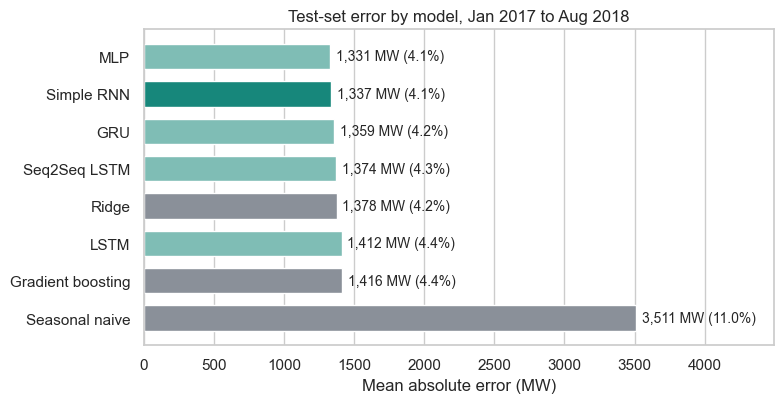

In [15]:
# Model comparison chart, sorted by test MAE
order = test_table.sort_values("MAE", ascending=False).index
order = [m for m in order if m != "Same hour yesterday"]   # far off the scale; its value is in the table
colors = [TEAL if m == FINAL else (GRAY if m not in DEEP else "#7FBDB5") for m in order]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(order, test_table.loc[order, "MAE"], color=colors, height=0.68)
ax.bar_label(bars, labels=[f"{v:,.0f} MW ({p:.1f}%)" for v, p in zip(test_table.loc[order, "MAE"], test_table.loc[order, "MAPE %"])],
             padding=4, fontsize=10)
ax.set(title="Test-set error by model, Jan 2017 to Aug 2018", xlabel="Mean absolute error (MW)")
ax.set_xlim(0, test_table.loc[order, "MAE"].max() * 1.28); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("figures/05_model_comparison.png", dpi=200); plt.show()

## Step 4. Report
### 4a. What the forecasts look like
We plot the final model against the seasonal-naive baseline on a summer and a winter week from the test set.

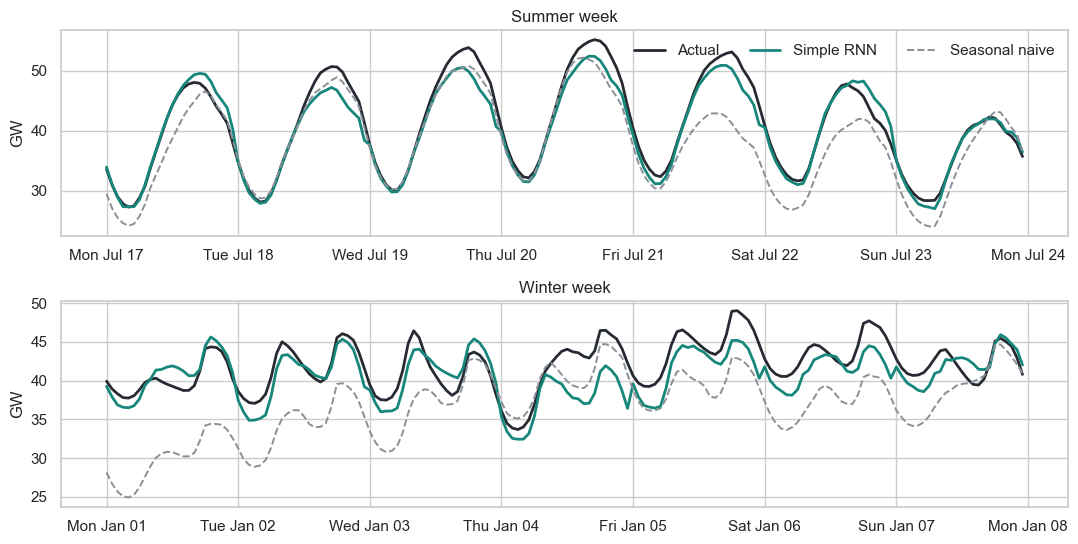

In [16]:
pred = forecasts_test[FINAL]
test_days = idx[test_o]
hourly = pd.DataFrame({"actual": actual_test.ravel(), "final": pred.ravel(),
                       "naive": forecasts_test["Seasonal naive"].ravel()},
                      index=pd.DatetimeIndex(np.concatenate([idx[o:o + HORIZON] for o in test_o])))

fig, axes = plt.subplots(2, 1, figsize=(11, 5.6))
for ax, (start, end, name) in zip(axes, [("2017-07-17", "2017-07-23", "Summer week"), ("2018-01-01", "2018-01-07", "Winter week")]):
    w = hourly[start:end] / 1000
    ax.plot(w.index, w["actual"], color="#262B33", lw=2, label="Actual")
    ax.plot(w.index, w["final"], color=TEAL, lw=2, label=FINAL)
    ax.plot(w.index, w["naive"], color=GRAY, lw=1.4, ls="--", label="Seasonal naive")
    ax.set(title=name, ylabel="GW")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %b %d")); ax.xaxis.set_major_locator(mdates.DayLocator())
axes[0].legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout(); plt.savefig("figures/06_forecast_examples.png", dpi=200); plt.show()

### 4b. Where the errors fall: testing H5

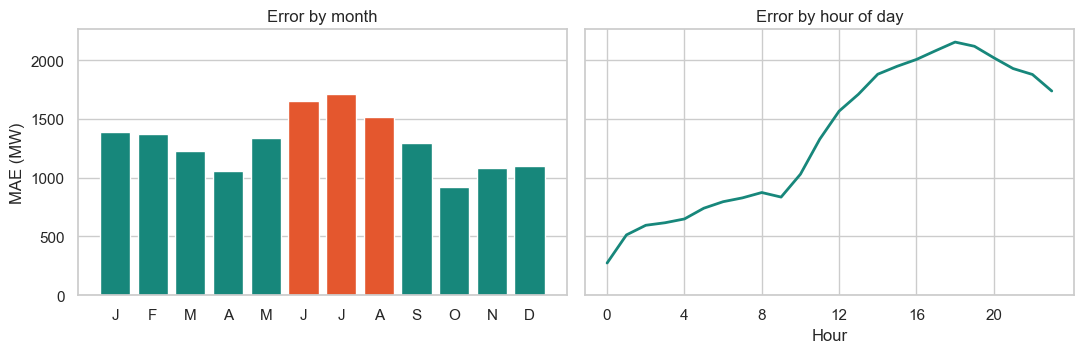

                 count    mean  median
group                                 
Federal holiday     15  1422.0  1191.0
Normal day         535  1311.0  1121.0
Top 5% peak day     29  1777.0  1661.0
Federal holiday vs. normal days: p = 0.1786
Top 5% peak day vs. normal days: p = 0.0001
Summer vs. other days: p = 0.0

MAE by season:
            abs_err   ape
Fall    1099.180054  3.65
Spring  1209.119995  4.13
Summer  1645.630005  4.54
Winter  1320.010010  4.00

MAE at 1 hour ahead 274 MW, at 24 hours ahead 1,737 MW

Five worst test days:
               mae     peak    bias    weekday  peak change vs. prior day
Datetime                                                                 
2017-05-20  6002.0  32175.0  5992.0   Saturday                   -15024.0
2018-06-22  4525.0  34629.0  4213.0     Friday                    -8377.0
2018-05-05  4460.0  30118.0  4460.0   Saturday                    -9384.0
2018-05-30  4361.0  37888.0  4361.0  Wednesday                    -4801.0
2018-07-06  4302.

In [17]:
hourly["abs_err"] = (hourly["final"] - hourly["actual"]).abs()
hourly["ape"] = 100 * hourly["abs_err"] / hourly["actual"]
by_month = hourly.groupby(hourly.index.month)["abs_err"].mean()
by_hour = hourly.groupby(hourly.index.hour)["abs_err"].mean()
by_horizon = pd.Series(np.abs(pred - actual_test).mean(axis=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
month_names = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
top = by_month.nlargest(3).index
axes[0].bar(range(12), by_month.values, color=[CORAL if m in top else TEAL for m in by_month.index])
axes[0].set_xticks(range(12)); axes[0].set_xticklabels(month_names)
axes[0].set(title="Error by month", ylabel="MAE (MW)"); axes[0].grid(axis="x", visible=False)
axes[1].plot(by_hour.index, by_hour.values, color=TEAL, lw=2)
axes[1].set(title="Error by hour of day", xlabel="Hour"); axes[1].set_xticks(range(0, 24, 4))
plt.tight_layout(); plt.savefig("figures/07_error_structure.png", dpi=200); plt.show()

# Compare day types: holidays and the top 5% of days by peak against all other days
day_err = pd.DataFrame({"mae": daily_mae[FINAL], "peak": actual_test.max(axis=1)}, index=test_days)
day_err["group"] = "Normal day"
day_err.loc[day_err["peak"] >= day_err["peak"].quantile(0.95), "group"] = "Top 5% peak day"
day_err.loc[day_err.index.isin(holidays), "group"] = "Federal holiday"
print(day_err.groupby("group")["mae"].agg(["count", "mean", "median"]).round(0).to_string())

# Mann-Whitney tests: are each group's daily errors higher than normal days?
normal = day_err.loc[day_err["group"] == "Normal day", "mae"]
for g in ["Federal holiday", "Top 5% peak day"]:
    print(g, "vs. normal days: p =", round(mannwhitneyu(day_err.loc[day_err["group"] == g, "mae"], normal, alternative="greater").pvalue, 4))
summer_day = day_err.index.month.isin([6, 7, 8])
print("Summer vs. other days: p =", round(mannwhitneyu(day_err.loc[summer_day, "mae"], day_err.loc[~summer_day, "mae"], alternative="greater").pvalue, 5))
print("\nMAE by season:")
season = hourly.index.month.map(lambda m: {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                           6: "Summer", 7: "Summer", 8: "Summer"}.get(m, "Fall"))
print(hourly.groupby(season)[["abs_err", "ape"]].mean().round(2).to_string())
print(f"\nMAE at 1 hour ahead {by_horizon.iloc[0]:,.0f} MW, at 24 hours ahead {by_horizon.iloc[-1]:,.0f} MW")
print("\nFive worst test days:")
day_err["bias"] = (pred - actual_test).mean(axis=1)         # positive = forecast too high
day_err["weekday"] = day_err.index.day_name()
day_err["peak change vs. prior day"] = day_err["peak"].diff()
print(day_err.nlargest(5, "mae")[["mae", "peak", "bias", "weekday", "peak change vs. prior day"]].round(0).to_string())
print("\nCorrelation of daily error with absolute day-over-day peak change:",
      round(day_err["mae"].corr(day_err["peak change vs. prior day"].abs()), 2))
# Share of total error that falls on the worst 10% of days
worst = day_err["mae"].nlargest(int(len(day_err) * 0.1)).sum() / day_err["mae"].sum()
print(f"\nWorst 10% of days carry {100 * worst:.0f}% of total error")

### 4c. Prediction intervals
Operators need a range, not just a point. We use **split conformal calibration**: for each horizon hour, the 5th and 95th
percentiles of the *validation* errors become a 90% band around the forecast. The test set then shows whether the band
really covers 90% of outcomes.

In [18]:
val_resid = actual_val - forecasts_val[FINAL]
q_lo, q_hi = np.percentile(val_resid, 5, axis=0), np.percentile(val_resid, 95, axis=0)
lower, upper = pred + q_lo, pred + q_hi
inside = (actual_test >= lower) & (actual_test <= upper)
print(f"90% band: average width {np.mean(upper - lower):,.0f} MW, test coverage {100 * inside.mean():.1f}%")
cov = pd.Series(inside.ravel(), index=hourly.index)
print("Coverage by season (%):", (100 * cov.groupby(season).mean()).round(1).to_dict())

# Refinement: calibrate separately per season, still using validation errors only
season_of = lambda days: np.array([{12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                    6: "Summer", 7: "Summer", 8: "Summer"}.get(m, "Fall") for m in days.month])
val_season, test_season = season_of(idx[val_o]), season_of(idx[test_o])
lower, upper = pred.copy(), pred.copy()
for s_name in np.unique(val_season):
    rows = test_season == s_name
    lower[rows] += np.percentile(val_resid[val_season == s_name], 5, axis=0)
    upper[rows] += np.percentile(val_resid[val_season == s_name], 95, axis=0)
inside = (actual_test >= lower) & (actual_test <= upper)
cov = pd.Series(inside.ravel(), index=hourly.index)
print(f"Season-calibrated band: average width {np.mean(upper - lower):,.0f} MW, test coverage {100 * inside.mean():.1f}%")
print("Coverage by season (%):", (100 * cov.groupby(season).mean()).round(1).to_dict())
print("Width by season (MW):", pd.Series((upper - lower).mean(axis=1)).groupby(test_season).mean().round(0).to_dict())

90% band: average width 4,787 MW, test coverage 86.6%
Coverage by season (%): {'Fall': 91.0, 'Spring': 89.9, 'Summer': 81.0, 'Winter': 85.5}
Season-calibrated band: average width 4,717 MW, test coverage 86.2%
Coverage by season (%): {'Fall': 87.6, 'Spring': 83.3, 'Summer': 85.4, 'Winter': 89.6}
Width by season (MW): {'Fall': 4228.0, 'Spring': 3888.0, 'Summer': 5692.0, 'Winter': 5026.0}


## Step 5. Act: apply the results
The operating question is how much capacity to hold above the forecast. For each day we measure how far the true peak
landed above the forecast peak. The 95th percentile of that shortfall is the **buffer needed to cover 95% of daily peaks**.
The buffer is set on the validation years and checked on the test set.

                Buffer from validation (MW)  Test peaks covered %
Seasonal naive                       9362.5                  93.6
Ridge                                4585.7                  92.7
Simple RNN                           4514.1                  94.5

Buffer reduction vs. seasonal naive: 4,848 MW


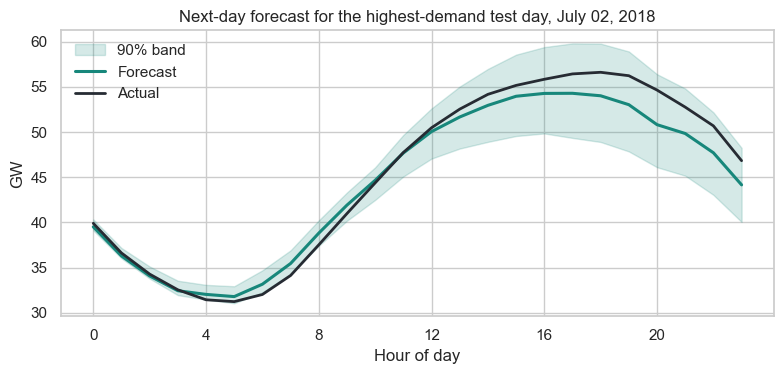

2018-07-02: actual peak 56,609 MW, forecast peak 54,286 MW


In [19]:
def peak_buffer(actual, forecast, q=95):
    """MW above the forecast peak needed to cover q% of daily peaks."""
    return np.percentile(actual.max(axis=1) - forecast.max(axis=1), q)


buffers = pd.DataFrame({
    m: {"Buffer from validation (MW)": peak_buffer(actual_val, forecasts_val[m]),
        "Test peaks covered %": 100 * np.mean(actual_test.max(axis=1) <= forecasts_test[m].max(axis=1) + peak_buffer(actual_val, forecasts_val[m]))}
    for m in dict.fromkeys(["Seasonal naive", "Ridge", BEST_RNN, FINAL])}).T
print(buffers.round(1).to_string())
saved = buffers.loc["Seasonal naive"].iloc[0] - buffers.loc[FINAL].iloc[0]
print(f"\nBuffer reduction vs. seasonal naive: {saved:,.0f} MW")

# Example day-ahead view: the highest-demand day in the test set, with its 90% band
k = int(np.argmax(actual_test.max(axis=1)))
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.fill_between(range(24), lower[k] / 1000, upper[k] / 1000, color=TEAL, alpha=0.18, label="90% band")
ax.plot(range(24), pred[k] / 1000, color=TEAL, lw=2.2, label="Forecast")
ax.plot(range(24), actual_test[k] / 1000, color="#262B33", lw=2, label="Actual")
ax.set(title=f"Next-day forecast for the highest-demand test day, {test_days[k]:%B %d, %Y}", xlabel="Hour of day", ylabel="GW")
ax.set_xticks(range(0, 24, 4)); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig("figures/08_peak_day_band.png", dpi=200); plt.show()
print(f"{test_days[k]:%Y-%m-%d}: actual peak {actual_test[k].max():,.0f} MW, forecast peak {pred[k].max():,.0f} MW")

### Hypothesis verdicts
| Hypothesis | Evidence | Verdict |
|---|---|---|
| H1 Strong cycles | Autocorrelation 0.89 at 24 h and 0.78 at 168 h; July averages 36% above April | Supported |
| H2 RNN beats baselines | Simple RNN beats seasonal naive by 2,174 MW and gradient boosting by 79 MW (both p < 0.001); its 40 MW lead over ridge is not significant (p = 0.12) | Partly supported |
| H3 Gated RNNs win | LSTM and GRU were significantly **worse** than the Simple RNN (by 75 and 22 MW) and the MLP (by 81 and 28 MW) | Not supported |
| H4 One week beats one day | Helped ridge (49 MW) and GRU (31 MW); no significant change for the other five models | Partly supported |
| H5 Errors at peaks and holidays | Summer and top-5% peak days have higher MW error (p < 0.001); holidays do not differ detectably (p = 0.18, 15 days) | Partly supported |

### Recommendations
* **Use the Simple RNN with a one-week window as the working forecast.** It had the lowest validation error, is the smallest
  network (21,144 parameters) and trains in about 2 minutes. Its test MAE is 1,337 MW (4.1%), 62% below the seasonal-naive forecast.
* **Keep ridge regression as the transparent backup.** Extra model complexity bought little here: the Simple RNN and the MLP
  are tied (p = 0.53), and the lead over ridge is within noise on MAE. The RNN's lower peak error (5.1% vs. 5.5%) was not formally tested.
* **Set reserves from measured error.** About 4,500 MW above the forecast peak covered 94.5% of test-day peaks. The
  seasonal-naive forecast would need about 9,400 MW. Ridge needs nearly the same as the RNN (4,586 MW), so this gain comes
  from moving beyond naive forecasts, not from the RNN specifically.
* **Recalibrate the bands often.** The 90% band covered only 86.6% of test hours (81.0% in summer), because test errors ran about
  16% above validation errors. Per-season calibration raised summer to 85.4% but lowered spring to 83.3%, so overall coverage did
  not improve. A rolling recalibration on recent errors is the next thing to try.
* **Add weather next.** The five worst days were all over-forecasts on days when the peak fell sharply from the day before,
  and daily error correlates with the size of that day-to-day change (r = 0.53). That pattern is consistent with sudden weather
  changes, but this dataset has no weather variable, so the cause is not confirmed.

### Limitations
* Forecasts are issued at midnight using load through 23:00. A real day-ahead market closes earlier, so a live system would be less accurate.
* The results cover one region and end in August 2018. Models were not refitted on the validation years before testing.
* Three seeds per network is a small sample, and many pairwise tests were run without correcting for multiple comparisons.
* The test set was seen once during the first design iteration (see Step 3d), so test scores may be slightly optimistic.
* Peak-day error is higher in MW, but those days also have higher load, so the percent error was not compared.